# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("/content/unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [4]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3 * 1) / (1024**2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
bytes_per_frame = 1920 * 1080 * 3
total_frames = frames_per_day * 400
fleet_tb = (bytes_per_frame * total_frames) / (1024**4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_width = 640
small_height = 360
small_fps = 10

small_bytes_per_frame = small_width * small_height * 3
small_frames_per_day = small_fps * 24 * 60 * 60
small_total_frames = small_frames_per_day * 400

fleet_tb_small = (small_bytes_per_frame * small_total_frames) / (1024**4)

pct_pixels_remaining = (
    (small_width * small_height) / (1920 * 1080)
) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

- Spatial evidence: Fine visual details such as a person’s face, clothing, or a small object in their hand may become blurred or disappear when the image is reduced to 360p.
- Temporal evidence: Important fast movements or brief events may occur between the 10-fps frames and never be recorded, making it impossible to know exactly what happened or in what order.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

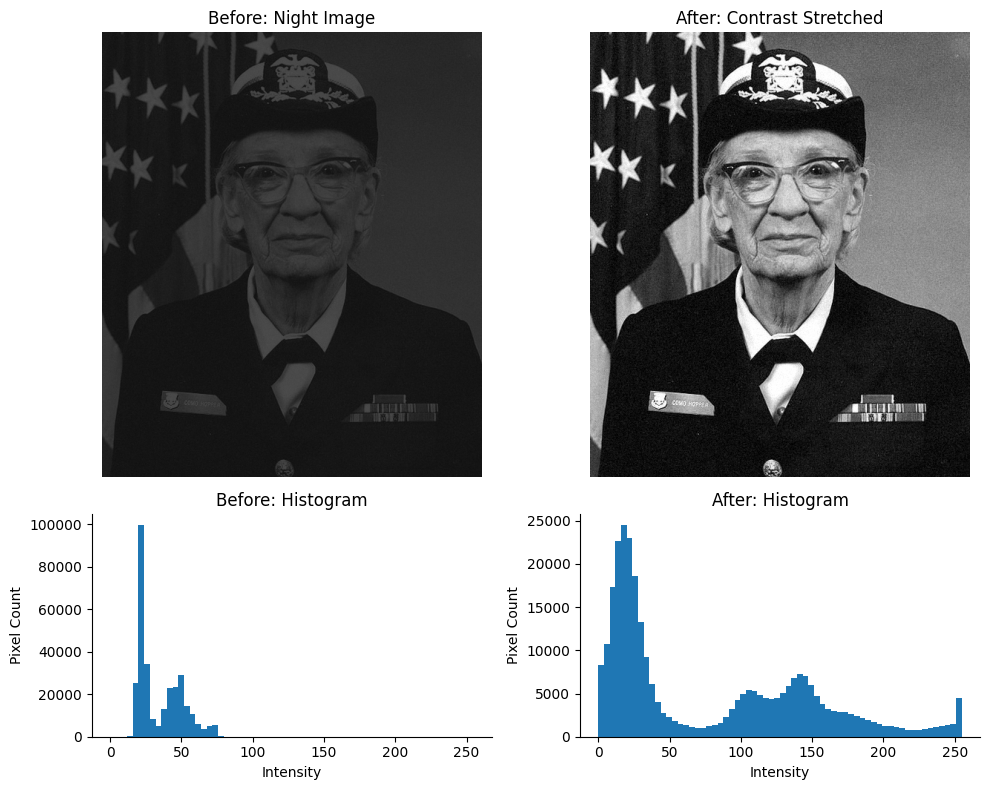

Contrast before: 0.609  ->  after: 1.000


In [5]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1 = np.percentile(night_still, 1)
p99 = np.percentile(night_still, 99)

c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = (night_still - p1) / (p99 - p1) * 255
stretched = np.clip(stretched, 0, 255)

c_after = michelson(
    np.percentile(stretched, 99),
    np.percentile(stretched, 1)
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)

# Original image
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Before: Night Image")
axes[0, 0].axis("off")

# Original histogram
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255))
axes[1, 0].set_title("Before: Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Pixel Count")

# Stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("After: Contrast Stretched")
axes[0, 1].axis("off")

# Stretched histogram
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255))
axes[1, 1].set_title("After: Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night image has a positively skewed / right-skewed histogram: most pixels are concentrated in the low-intensity (dark) range, with a smaller number of pixels extending toward higher intensities.
Stretching did not create new information. It simply expanded the existing intensity range from a narrow dark range toward the full 0–255 range. This increased the contrast between dark and bright pixels, making details such as the face, uniform, and background easier to see.
A histogram only tells us how many pixels have each intensity, not where those pixels are located. Therefore, it cannot tell us what the image contains. Two completely different images can have the same histogram but different spatial arrangements of their pixels — this is the “Same Histogram ≠ Same Image” idea.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing ranges:
68.70s -> 68.70s
68.77s -> 68.77s
68.87s -> 70.53s
70.60s -> 70.83s
70.90s -> 71.13s
71.20s -> 71.63s
71.70s -> 72.03s
72.10s -> 72.13s
72.23s -> 72.73s
72.80s -> 73.23s
73.30s -> 73.73s
73.80s -> 73.90s
73.97s -> 74.03s
74.10s -> 74.23s
74.30s -> 74.67s
74.73s -> 75.37s
75.43s -> 75.47s
75.53s -> 75.57s
75.63s -> 75.67s
75.73s -> 75.73s
75.80s -> 75.90s
75.97s -> 76.53s
76.63s -> 76.93s
77.00s -> 78.10s

Running ranges:
78.60s -> 86.00s

Audio event frame: 2250
Lighting event frame: 3000


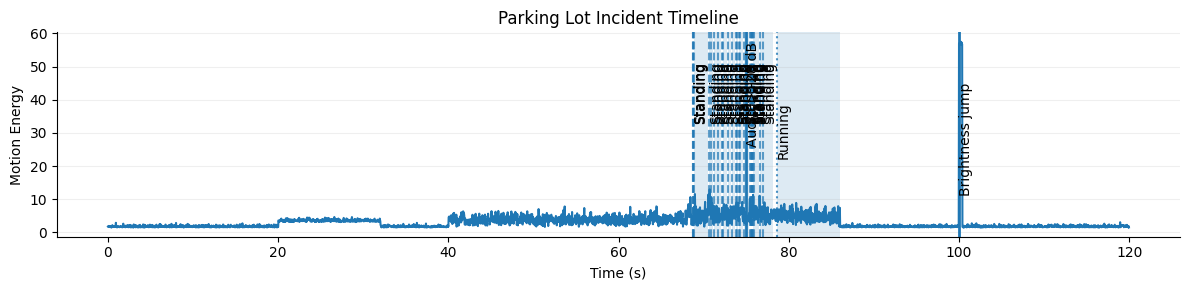



In [6]:

# TODO 1: person speed (px/s)

# Difference over 1 second = FPS frames
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)

speed = np.sqrt(dx**2 + dy**2)

# Store it in the dataframe for convenience
cctv["person_speed"] = speed


# TODO 2: standing / running time ranges

standing = (
    cctv["person_x"].notna() &
    cctv["person_y"].notna() &
    (speed < 3)
)

running = (
    cctv["person_x"].notna() &
    cctv["person_y"].notna() &
    (speed > 25)
)


# Helper function to find continuous time ranges
def get_ranges(mask):
    ranges = []
    start = None

    for i, value in enumerate(mask):
        if value and start is None:
            start = i

        elif not value and start is not None:
            ranges.append((start, i - 1))
            start = None

    # Handle a range that continues to the last frame
    if start is not None:
        ranges.append((start, len(mask) - 1))

    return ranges


standing_ranges = get_ranges(standing)
running_ranges = get_ranges(running)


print("Standing ranges:")
for start, end in standing_ranges:
    print(
        f"{cctv.iloc[start].time_s:.2f}s -> "
        f"{cctv.iloc[end].time_s:.2f}s"
    )

print("\nRunning ranges:")
for start, end in running_ranges:
    print(
        f"{cctv.iloc[start].time_s:.2f}s -> "
        f"{cctv.iloc[end].time_s:.2f}s"
    )


# TODO 3: event frame indices

# First frame where audio rises above -20 dB
audio_hits = np.where(cctv["audio_level_db"].values > -20)[0]

audio_event_idx = int(audio_hits[0]) if len(audio_hits) > 0 else None


# First frame where brightness increases by more than 40
brightness_jump = cctv["mean_brightness"].diff()

lighting_hits = np.where(brightness_jump.values > 40)[0]

lighting_event_idx = (
    int(lighting_hits[0]) if len(lighting_hits) > 0 else None
)


print(f"\nAudio event frame: {audio_event_idx}")
print(f"Lighting event frame: {lighting_event_idx}")


# TODO 4: annotated motion-energy timeline

fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(
    cctv["time_s"],
    cctv["motion_energy"],
    label="Motion energy"
)

# Mark standing ranges
for n, (start, end) in enumerate(standing_ranges):
    t_start = cctv.iloc[start].time_s
    t_end = cctv.iloc[end].time_s

    ax.axvspan(
        t_start,
        t_end,
        alpha=0.15
    )

    ax.axvline(t_start, linestyle="--", alpha=0.7)
    ax.text(
        t_start,
        ax.get_ylim()[1] * 0.85,
        "Standing",
        rotation=90,
        va="top"
    )


# Mark running ranges
for n, (start, end) in enumerate(running_ranges):
    t_start = cctv.iloc[start].time_s
    t_end = cctv.iloc[end].time_s

    ax.axvspan(
        t_start,
        t_end,
        alpha=0.15
    )

    ax.axvline(t_start, linestyle=":", alpha=0.8)
    ax.text(
        t_start,
        ax.get_ylim()[1] * 0.65,
        "Running",
        rotation=90,
        va="top"
    )


# Mark audio event
if audio_event_idx is not None:
    t = cctv.iloc[audio_event_idx].time_s

    ax.axvline(
        t,
        linewidth=2
    )

    ax.text(
        t,
        ax.get_ylim()[1] * 0.95,
        "Audio > -20 dB",
        rotation=90,
        va="top"
    )


# Mark lighting event
if lighting_event_idx is not None:
    t = cctv.iloc[lighting_event_idx].time_s

    ax.axvline(
        t,
        linewidth=2
    )

    ax.text(
        t,
        ax.get_ylim()[1] * 0.75,
        "Brightness jump",
        rotation=90,
        va="top"
    )


ax.set_title("Parking Lot Incident Timeline")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion Energy")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


# TODO 5: one keyframe per event

# Collect representative frames:
# - first frame of each standing range
# - first frame of each running range
# - audio event
# - lighting event

event_indices = []

for start, end in standing_ranges:
    event_indices.append(("Standing", start))

for start, end in running_ranges:
    event_indices.append(("Running", start))

if audio_event_idx is not None:
    event_indices.append(("Audio event", audio_event_idx))

if lighting_event_idx is not None:
    event_indices.append(("Lighting event", lighting_event_idx))


# Remove duplicate frame indices
unique_events = []
seen = set()

for label, idx in event_indices:
    if idx not in seen:
        unique_events.append((label, idx))
        seen.add(idx)


# Display keyframes
if unique_events:
    fig, axes = plt.subplots(
        1,
        len(unique_events),
        figsize=(4 * len(unique_events), 4)
    )

    # If there is only one event, axes isn't an array
    if len(unique_events) == 1:
        axes = [axes]

    for ax, (label, idx) in zip(axes, unique_events):
        frame = render_frame(cctv.iloc[idx])

        ax.imshow(frame)
        ax.set_title(
            f"{label}\n"
            f"t = {cctv.iloc[idx].time_s:.2f}s"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No events detected.")

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

If I used uniform keyframes every 20 seconds, the short events around 70–86 seconds would most likely be missed, especially the standing-to-running transition and the brief activity around the audio event at about 75 s. The 20-second samples might only capture frames at roughly 60 s, 80 s, 100 s, etc., so short events between those points could disappear.
Instead, I used content-based keyframe extraction — selecting frames based on meaningful changes or events such as motion, audio, and brightness. This is the content-based keyframe selection approach from Slide 40.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

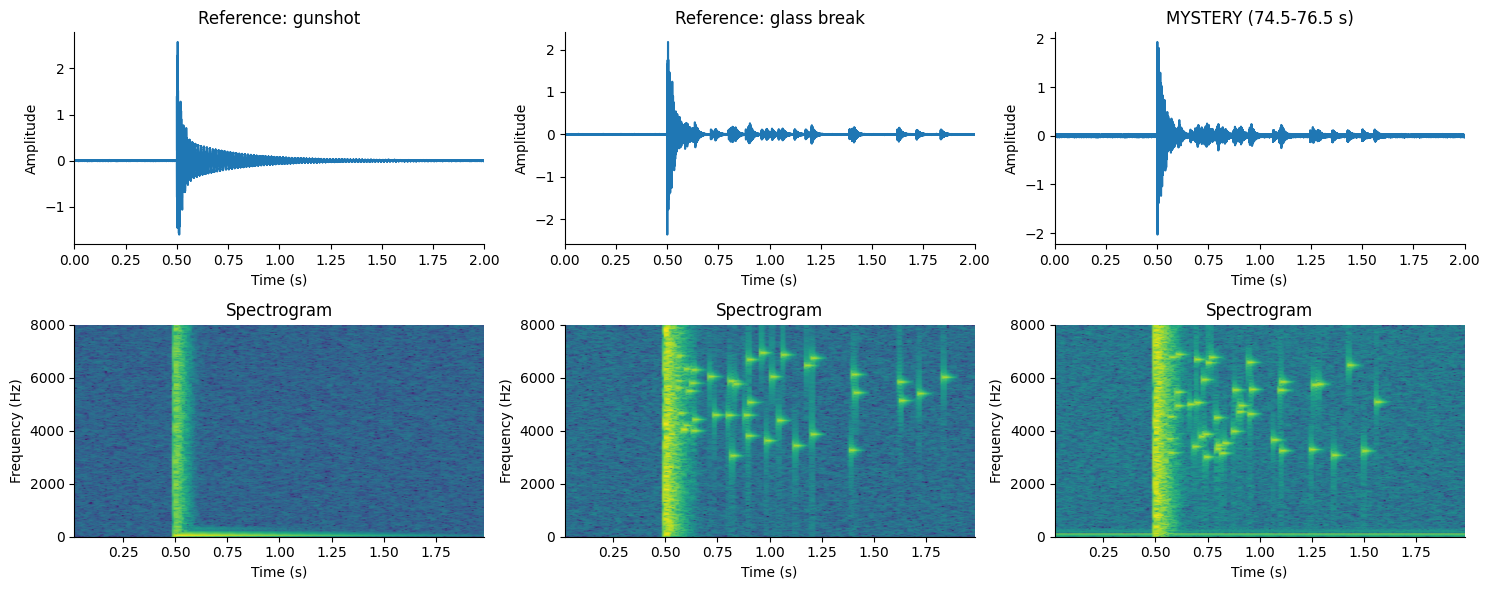

{'Reference: gunshot': np.float64(0.2153681288033536), 'Reference: glass break': np.float64(0.6377676959141664), 'MYSTERY (74.5-76.5 s)': np.float64(0.6562646133216414)}
Verdict: GLASS BREAK (mystery high-frequency energy fraction = 0.656)


In [7]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform and spectrogram for each clip

for col, (name, x) in enumerate(clips.items()):

    # -------------------------
    # TOP: Waveform
    # -------------------------
    t = np.arange(len(x)) / FS

    axes[0, col].plot(t, x)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_xlim(0, 2)

    # -------------------------
    # BOTTOM: Spectrogram
    # -------------------------
    f, t_spec, Sxx = signal.spectrogram(
        x,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    # Convert power to dB
    Sxx_db = 10 * np.log10(Sxx + 1e-12)

    axes[1, col].pcolormesh(
        t_spec,
        f,
        Sxx_db,
        shading="gouraud"
    )

    axes[1, col].set_title("Spectrogram")
    axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_ylim(0, 8000)


plt.tight_layout()
plt.show()


# TODO 3: fraction of energy above 3 kHz
# during 0.2–1.2 seconds after the impact

hf_fraction = {}

for name, x in clips.items():

    f, t_spec, Sxx = signal.spectrogram(
        x,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    # Select 0.2–1.2 seconds after impact
    time_mask = (t_spec >= 0.2) & (t_spec <= 1.2)

    # Select frequencies above 3 kHz
    high_freq_mask = f > 3000

    # Total spectral energy in the selected time period
    total_energy = Sxx[:, time_mask].sum()

    # Energy above 3 kHz
    high_freq_energy = Sxx[
        high_freq_mask,
        :
    ][:, time_mask].sum()

    hf_fraction[name] = high_freq_energy / total_energy


print(hf_fraction)


# TODO 4: verdict

gunshot_hf = hf_fraction["Reference: gunshot"]
glass_hf = hf_fraction["Reference: glass break"]
mystery_hf = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_hf - glass_hf) < abs(mystery_hf - gunshot_hf):
    verdict = "GLASS BREAK"
else:
    verdict = "GUNSHOT"

print(
    f"Verdict: {verdict} "
    f"(mystery high-frequency energy fraction = {mystery_hf:.3f})"
)

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No. Looking only at the waveforms, I could not confidently distinguish the gunshot from the glass break because both have a sharp impact around 0.5 s followed by a decaying signal.
The spectrogram adds three dimensions: time, frequency, and spectral energy/intensity. It shows not just when the sound occurs, but which frequencies are present and how strong they are over time.
The deciding pattern was the scattered high-frequency specks after the initial impact, extending above 3 kHz. This lingering high-frequency activity matches the glass-break reference, so the mystery sound is glass breaking, not a gunshot.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

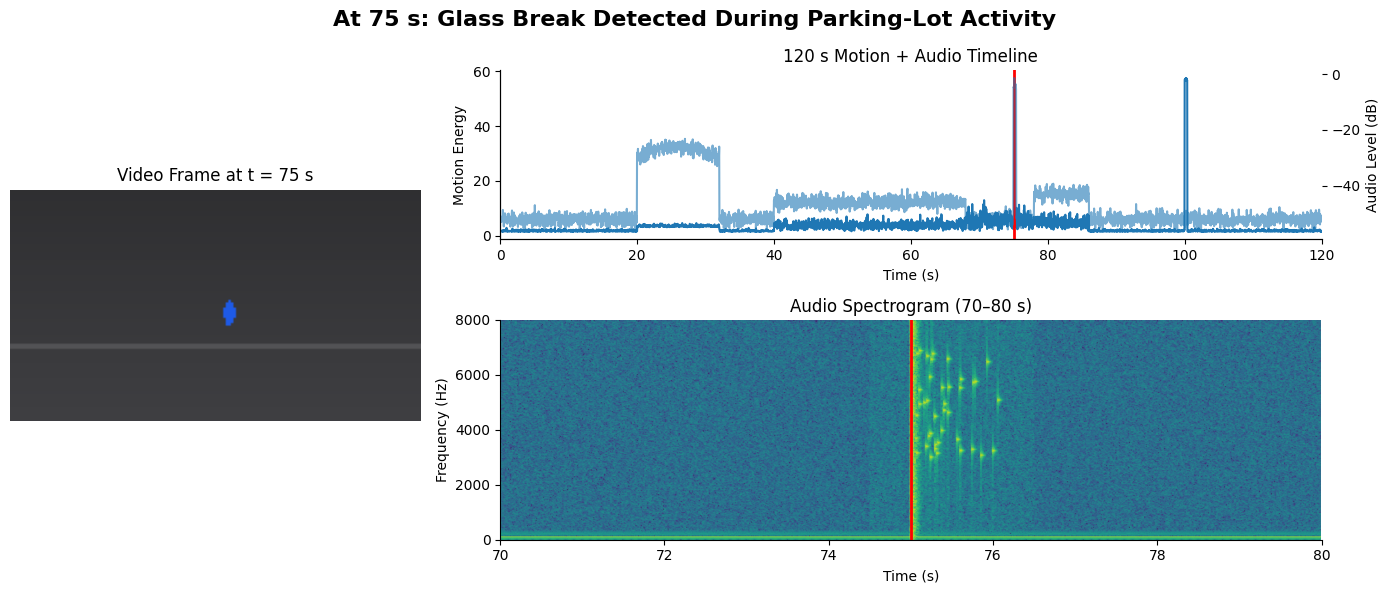

In [8]:
t_sel = 75.0

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: rendered video frame at t = 75 s
frame_idx = int(t_sel * FPS)
frame = render_frame(cctv.iloc[frame_idx])

ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(frame)
ax_frame.set_title("Video Frame at t = 75 s")
ax_frame.axis("off")


# TODO 2: full 120 s motion + audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])

ax_timeline.plot(
    cctv["time_s"],
    cctv["motion_energy"],
    label="Motion energy"
)

# Plot audio level on a second y-axis
ax_audio = ax_timeline.twinx()

ax_audio.plot(
    cctv["time_s"],
    cctv["audio_level_db"],
    alpha=0.6,
    label="Audio level"
)

# Red marker at 75 s
ax_timeline.axvline(
    t_sel,
    color="red",
    linewidth=2,
    label="t = 75 s"
)

ax_timeline.set_title("120 s Motion + Audio Timeline")
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion Energy")
ax_audio.set_ylabel("Audio Level (dB)")

ax_timeline.set_xlim(0, 120)


# TODO 3: spectrogram of x_audio from 70–80 s
ax_spec = fig.add_subplot(gs[1, 1])

# Select 70–80 s from the full audio
audio_mask = (t_audio >= 70) & (t_audio <= 80)
audio_segment = x_audio[audio_mask]

# Spectrogram
f, t_spec, Sxx = signal.spectrogram(
    audio_segment,
    fs=FS,
    nperseg=512,
    noverlap=384
)

# Convert power to dB
Sxx_db = 10 * np.log10(Sxx + 1e-12)

# Convert spectrogram time to absolute time
t_spec_absolute = t_spec + 70

ax_spec.pcolormesh(
    t_spec_absolute,
    f,
    Sxx_db,
    shading="gouraud"
)

ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)

# Same red marker at 75 s
ax_spec.axvline(
    t_sel,
    color="red",
    linewidth=2
)

ax_spec.set_title("Audio Spectrogram (70–80 s)")
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")


# TODO 4: conclusion-style title

fig.suptitle(
    "At 75 s: Glass Break Detected During Parking-Lot Activity",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio track were offset by +2 seconds, the audio event would appear at about 77 s while the corresponding visual event actually happened at 75 s. This would make the security team incorrectly associate the sound with a later video event and could lead to the wrong interpretation of what happened. The synchronized view, especially the top-right timeline and bottom-right spectrogram, would make the error visible because their red 75 s markers would no longer line up with the acoustic event. Correct synchronization is therefore essential when combining modalities.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At approximately 75 s, the parking-lot footage shows activity accompanied by a sharp acoustic event, and the spectrogram identifies the sound as glass breaking rather than a gunshot. I would put the synchronized image–video–audio view first because it connects the event's visual and acoustic evidence through a common time reference, following the lecture's structure → pattern → change → event → meaning idea. The content-based keyframes and spectrogram then provide detail without requiring the team to watch the entire two-minute recording. For storage, I recommend downsampling to 640×360 at 10 fps where appropriate, reducing the fleet's uncompressed requirement from about 5.87 PB/day to 217 TB/day. However, the policy must not sacrifice brief temporal events, because reducing the frame rate could permanently miss a short action or its exact timing.